# Chapter 7: Image Classification

## Preparing the Data

Will be creating a model to classify images from the CIFAR-10 dataset:
- Dataset consits of 60,000 tiny 32x32 RGB images
- Each image is labeled with an integer corresponding to 1 of 10 classes: \
airplane (0), automobile (1), bird (2), cat (3), deer (4), dog (5), frog (6), horse (7), ship (8), and truck (9).
- Example: \
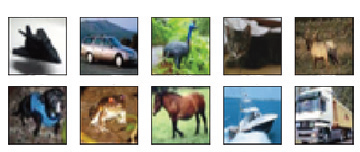

### Loading the Data with Torchvision

- Torchvision can create the dataset for the data, automatically downloading it if not present

In [18]:
import torch
from torchvision import datasets 
data_path = 'data/ch7'  # Path to data -- Will download here
cifar10 = datasets.CIFAR10(data_path, train=True, download=True) # Create Training Dataset, downloading data to data_path, if not present.
cifar10_val = datasets.CIFAR10(data_path, train=False, download=True) # Create Validation Dataset

# List to map integer label to its corresponding class
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

Files already downloaded and verified
Files already downloaded and verified


In [19]:
# Dataset returned as subclass of torch.utils.data.Dataset
type(cifar10).__mro__
# type(cifar10)

(torchvision.datasets.cifar.CIFAR10,
 torchvision.datasets.vision.VisionDataset,
 torch.utils.data.dataset.Dataset,
 typing.Generic,
 object)

#### PyTorch Datasets

All Dataset Objects (such as CIFAR10) have two main methods:
- **__ len __**: Returns # items in dataset
- **__ getitem __**: Returns item at the given index --> A sample with its corresponding label

Train Set: 50000, Val Set: 10000


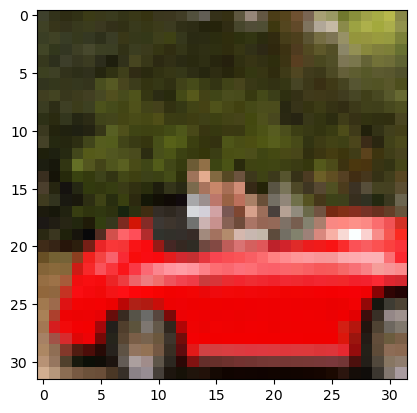

In [20]:
import matplotlib.pyplot as plt

# Number of items in dataset
print(f'Train Set: {len(cifar10)}, Val Set: {len(cifar10_val)}')

# Sample from the dataset
img, label = cifar10[99]  # PIL (Python Image Library) image, label
img, label, class_names[label]

# Plot Image
plt.imshow(img)
plt.show()

### Transforming the data to tensors

- Torchvision transforms imports functions that can be passed as an argument to the dataset constructor to preform transformations on the data
- transforsms=ToTensor() converts numpy arrays and PIL images to tensors \
--> Also handles transposing tensor dimensions to match expected format (C x H x W)

In [21]:
from torchvision import transforms
dir(transforms)

# Transforming the sample img
to_tensor = transforms.ToTensor()
img_t = to_tensor(img)
img_t.shape

# Transforming whole dataset
tensor_cifar10 = datasets.CIFAR10(data_path, train=True, download=True, transform=transforms.ToTensor())
tensor_cifar10_val = datasets.CIFAR10(data_path, train=False, download=True, transform=transforms.ToTensor())

Files already downloaded and verified
Files already downloaded and verified


In [22]:
img_t, _ = tensor_cifar10[99]
type(img_t)

# Shape is C x H x W and data type is float32 -- Expected
img_t.shape, img_t.dtype

(torch.Size([3, 32, 32]), torch.float32)

Note: While the PIL image channel values ranged from 0 to 255 (8-bit int), the transformed tensors values are scaled to range from 0.0 to 1.0 (32-bit float).  

However, we still get the same image.

Min: tensor(0.) Max: tensor(1.)


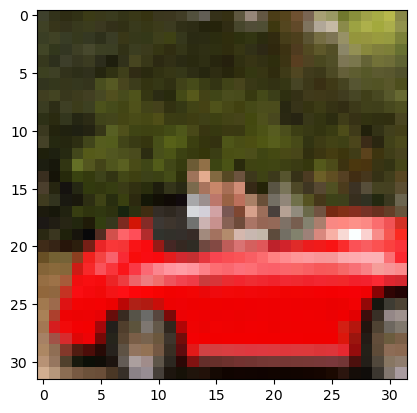

In [23]:
print('Min:', img_t.min(), 'Max:', img_t.max())

plt.imshow(img_t.permute(1, 2, 0)) # Rearrange dimentions to that expected by matplotlib
plt.show()

### Normalizing Data

- Transforms can also handle data normalization and augemtation
- We can chain transforms using the transforms.compose(...) function
- Why we nomalize data -- the intuition:
1. Since the activation functions are linear around 0 or +/- 1, keeping the data in the same range allows the neurons to learn faster, as its more likely the neurons will be in the saturated range (non-zero grads)
2. Normalization also ensures that gradient descent, with the same learning rate will work well across all parameter (channels), without a single one dominating the models learning process (if its values are much higher than others). This also allows for data to be shuffled, which helps with overfitting.


- transforms.normalise() preforms z-score nomalisation on the data (v_n[c] = (v[c] - mean[c]) / stdev[c]) \
- **Requires you to pass the mean and standard deviation** as input (Not computed by the transform)

In [24]:
# Stack the dataset tensors in a new tensor -- used to calculate mean and std 
imgs = torch.stack([img_t for img_t, _ in tensor_cifar10], dim = 3)
imgs.shape

torch.Size([3, 32, 32, 50000])

In [25]:
# Compute the mean of each channel -- Across all images
mean = imgs.view(3, -1).mean(dim=1) # recall: View(3, -1) will keep the 3 channels (RGB) and merge all the other dimentions into one. image.shape = 3, 24 x 24 x 50000 = 3, 28800000

# Compute standard deviation -- Across all images: Same method
std = imgs.view(3, -1).std(dim=1) # dim 1 will compute std across all images for each channel

print(f'Mean: {mean}, STD: {std}')
# mean.tolist()

# Initilaize the normalize transform
transforms.Normalize((0.4914, 0.4822, 0.4465), 
                     (0.2470, 0.2435, 0.2616)) # .Normalize((mean), (std))

# Remember this line from ch2 -- Now we understand it!

Mean: tensor([0.4914, 0.4822, 0.4465]), STD: tensor([0.2470, 0.2435, 0.2616])


Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))

### Combining the transforms with compose  

In [106]:
transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean.tolist(), 
                         std=std.tolist()), # tolist() extracts mean and std list from the tensor
    # transforms.RandomCrop(10) #Added for excersie 1
                         ])

transformed_cifar10 = datasets.CIFAR10(data_path, train=True, download=True, transform=transform)
transformed_cifar10_val = datasets.CIFAR10(data_path, train=False, download=True, transform=transform)

Files already downloaded and verified
Files already downloaded and verified


Note: After nomalization, plotting the image will not show an accureate representation

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.5570878..0.3126225].


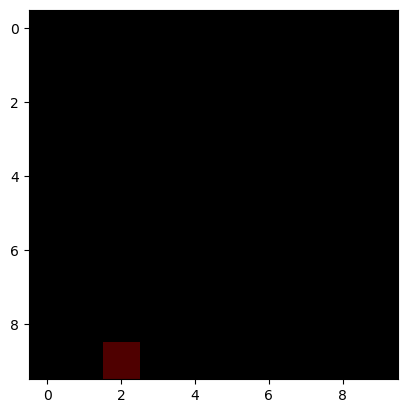

In [27]:
img_t, _ = transformed_cifar10[99]

plt.imshow(img_t.permute(1, 2, 0))
plt.show()

## Building the Network: Telling birds from airplanes

### Building the dataset from CIFAR10
- Filtering data of birds and airplanes from CIFAR10 and remaping lables (to be contiguous)
- Dataset dosen't have to be a torch dataset subclass

In [132]:
label_map = {0:0, 2:1} #Remaps label 2 (birds) in CIFAR dataset to be label 1 for our dataset
class_names = ['airplane', 'bird'] #Corresponding name for each label

# Creating the mini dataset
cifar2 = [(img, label_map[label]) for img, label in transformed_cifar10
          if label in [0, 2]] #Filters out birds and airplanes in cifar10 and adds them to new list (dataset)
cifar2_val = [(img, label_map[label]) for img, label in transformed_cifar10_val
              if label in [0, 2]]

### Building the Network

- An image is a set of numbers in a (2D) spacial configuration
- To "remove" the spacial configuration, we can take the image pixels and straighten them into a 1D vector, with each value in the vector being an input feature for the network. \
  --> In this case 32 x 32 x 3 = 3072 features per sample image
- Now, we can build our network: \
--> Linear layer with 3072 input feature (and some hidden layers) --> an activation --> final linear layer with 2 outputs (0 for airplane, 1 for bird)

In [49]:
import torch.nn as nn

n_in = 24 * 24 * 3  # Input input features (C x W x H)
n_in = cifar2[0][0].numel() # Automatically get # elements (input features) from sample image 
n_out = 2  # Classes to predict from

n_hidden = 512

model = nn.Sequential(nn.Linear(n_in, n_hidden), 
                      nn.Tanh(),
                      nn.Linear(n_hidden, n_out))

#### Outputing Probablilites

- A clasifier won't be perfect, so the output of the network is the probability of identifying that class \
Since the network outputs probabilities note that: \
-->Each element must be in the range [0.0 to 1.0] \
--> All elements must sum to 1.0

- The softmax function take a vector of values and produces a (same size) vector of probabilities,  satisfing the above. \
--> Converts a vector of K real numbers into a probability distribution of K possible outcomes

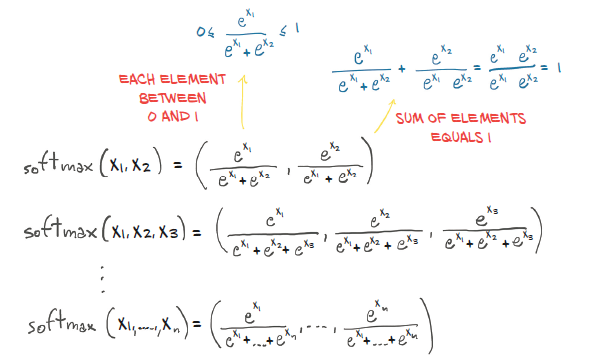

In [31]:
# Creating the softmax function -- take the elements of the vector, compute the elementwise exponential, and divide each element by the sum of exponentials 
def softmax(x):
    return torch.exp(x) / torch.exp(x).sum()

# Testing on an input vector
x = torch.tensor([1.0, 2.0, 3.0])
softmax(x)
softmax(x).sum()

# Using the softmax function provided with torch.nn -- Have to specify dim to preform softmax on
softmax = nn.Softmax(dim=1)
x = torch.tensor([[1.0, 2.0, 3.0], # 2 input vectors in 2 rows: just like a batch
                 [1.0, 2.0, 3.0]])

softmax(x)

tensor([[0.0900, 0.2447, 0.6652],
        [0.0900, 0.2447, 0.6652]])

Adding Softmax to model and Seeing output

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.377191..1.5630796].


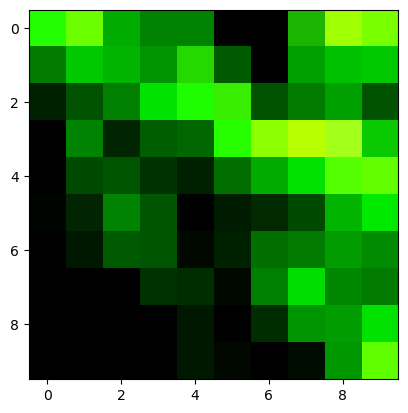

In [36]:
# Adding softmax function to model to output probabilities
model = nn.Sequential(
    nn.Linear(n_in, n_hidden),
    nn.Tanh(),
    nn.Linear(n_hidden, n_out),
    nn.Softmax(dim=1))

# Running the model (before training) to see output
img, _ = cifar2[0]

plt.imshow(img.permute(1, 2, 0))
plt.show()

In [37]:
# Turning image into a 1D tensor and adding an extra dim (at dix 0) for batch size -- Expected model input
img_batch = img.view(-1) # Converts tensor to 1D
img, img_batch

img_batch = img_batch.unsqueeze(0) # Add dim for batch
img_batch.shape

# Invoke the model on the data
out = model(img_batch)
out

RuntimeError: view size is not compatible with input tensor's size and stride (at least one dimension spans across two contiguous subspaces). Use .reshape(...) instead.

Using torch.max to determin index/label of class with highest predicted probability \
--> Output of .max() = maximum element (along given dim), index of that element \
--> Must specify dim to compute max on, like other tensor functions  

In [38]:
_, index = torch.max(out, dim=1)
index

# Printing label corresponding to class
class_names[index]

NameError: name 'out' is not defined

### A loss functions for probablitites

- Since we're interested in penalizing misclassifications rather than everything that dosen't look like exactly 0.0 or 1.0, MSELoss won't work well.
- For classification tasks and probabilities, the loss function should be very high when the likelyhood (probability associated with correct class on out[true_label]) is low, and low when the likelyhood is high. \
-->out[true_label] outputs the prediction probability of the ground truth label. If it's low, the loss should be high.

- We can use the NLL (Negative Log Likelihood) loss function which does just that \
--> NLL = - sum(log(out_i[c_i])), where the sum is taken over N samples and c_i is the correct class for sample i. \
--> Since inputs are probabilities, as the likelyhood of one grows, other probabilites must decrease

**Note: NLL takes LOG probabilites as inputs.** -- It does this because as probabilites approach 0, logs of those probabilites are hard to compute. \
--> To workaround this, replace the softmax function with a LogSoftmax function

***Overall Clasification Loss Process:*** \
For each Sample in batch
1. Run forward pass through model and obtain output of last (linear) layer (called logit)
2. Compute softmax of logit (outputs) to get probability
3. Take the predicted probability of the ground truth class (known as this is a supervised problem)
4. Compute its logarithm, multiply by -1 (to get -) and add that to the loss value

In [39]:
# Modifying model to use LogSoftmax
model = nn.Sequential(
    nn.Linear(n_in, n_hidden),
    nn.Tanh(),
    nn.Linear(n_hidden, n_out),
    nn.LogSoftmax(dim=1))

# Instantiate the NLL loss funct.
loss = nn.NLLLoss()

# Testing the loss funct.
img, label = cifar2[0]

# out = model(img.view(-1).unsqueeze(0))

loss(out, torch.tensor([label])) #loss(model output (log. prob.), tensor of class idxs (truth_label))
#outputs high loss as the models prediction is almost 50/50

NameError: name 'out' is not defined

### Training the Classifier

There is a small change in the training loop. -- We train the model on 1 sample at a time, Instead of evaluating all 10000 imgs.
--> More resonable for compute, but not ideal as grads are v. parial estimate
The only other thing that has changed is the model and the loss function.

In [40]:
import torch
import torch.nn as nn
import torch.optim as optim

# Classifier Model
model = nn.Sequential(
    nn.Linear(n_in, n_hidden),
    nn.Tanh(),
    nn.Linear(n_hidden, n_out),
    nn.LogSoftmax(dim=1))

learning_rate = 1e-2

# Normal Gradient decent optimizer
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

# NLL function to score (and optimize) probabilities
loss_fn = nn.NLLLoss()

n_epochs = 100

device = "cuda" if torch.cuda.is_available() else "cpu"

model.to(device)

# def training_loop(n_epochs, model, loss_fn, optimizer, cifar2):
for epoch in range(1, n_epochs+1):
    # for img, label in cifar2:
    img = img.to(device)
    img = img.view(-1).unsqueeze(0) # Straighten image into 1D tensor (and add dim for batch_size)
    out = model(img)
    loss = loss_fn(out, torch.tensor([label]).to(device))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    print("Epoch: %d, Loss %f" % (epoch, float(loss))) # Prints loss for LAST img in epoch

Epoch: 1, Loss 0.590474
Epoch: 2, Loss 0.275394
Epoch: 3, Loss 0.174892
Epoch: 4, Loss 0.127539
Epoch: 5, Loss 0.100171
Epoch: 6, Loss 0.082378
Epoch: 7, Loss 0.069896
Epoch: 8, Loss 0.060663
Epoch: 9, Loss 0.053559
Epoch: 10, Loss 0.047925
Epoch: 11, Loss 0.043351
Epoch: 12, Loss 0.039562
Epoch: 13, Loss 0.036374
Epoch: 14, Loss 0.033655
Epoch: 15, Loss 0.031308
Epoch: 16, Loss 0.029263
Epoch: 17, Loss 0.027465
Epoch: 18, Loss 0.025871
Epoch: 19, Loss 0.024450
Epoch: 20, Loss 0.023174
Epoch: 21, Loss 0.022023
Epoch: 22, Loss 0.020979
Epoch: 23, Loss 0.020028
Epoch: 24, Loss 0.019157
Epoch: 25, Loss 0.018359
Epoch: 26, Loss 0.017622
Epoch: 27, Loss 0.016942
Epoch: 28, Loss 0.016312
Epoch: 29, Loss 0.015725
Epoch: 30, Loss 0.015179
Epoch: 31, Loss 0.014669
Epoch: 32, Loss 0.014191
Epoch: 33, Loss 0.013743
Epoch: 34, Loss 0.013322
Epoch: 35, Loss 0.012925
Epoch: 36, Loss 0.012551
Epoch: 37, Loss 0.012198
Epoch: 38, Loss 0.011863
Epoch: 39, Loss 0.011546
Epoch: 40, Loss 0.011246
Epoch: 41

### Training on Minibatches

- To better represent the data in the grad, for each epoch shuffle the dataset and split into minibatches, accumulate grad over minibatches, and at the end, update params.
- Minibatches are typically a constant size -- Hyperparameter
- The DataLoader Module (torch.utils.data.DataLoader) is used to create minibatches and shuffle data.
--> Can be itterated over, so can use in training loop just like any dataset

- Aside: Using pinned (page-locked) memory for dataset allows faster GPU transfers
--> setting pin_memory_device to GPU loads data directly into GPU memory instead of first storing it in CPU RAM

In [50]:
# Creating minibatch loader from data
train_loader = torch.utils.data.DataLoader(cifar2, batch_size=64, shuffle=True, pin_memory=True, pin_memory_device=device) # DataLoader(dataset, batch_size, shuffle at beginning of each epoch?)
model.to(device)

# Updating training loop to use minibatches (dataLoader)
for epoch in range(1, n_epochs + 1):
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device) # moving to GPU for 
        batch_size = imgs.shape[0]  # imgs.shape = 64 x 3 x 32 x 32
        imgs = imgs.view(batch_size, -1) # Flattining the image, but leaving the batch size -- using view to combine everything but batch_size
        outputs = model(imgs)
        loss = loss_fn(outputs, labels) #Label converted to tensor in dataloader
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    print('Epoch %d, Loss: %f' % (epoch, float(loss))) # Loss now prints for random img in dataset

Epoch 1, Loss: 0.672215
Epoch 2, Loss: 0.561788
Epoch 3, Loss: 0.678567
Epoch 4, Loss: 0.795356
Epoch 5, Loss: 0.687301
Epoch 6, Loss: 0.646064
Epoch 7, Loss: 0.558956
Epoch 8, Loss: 0.642280
Epoch 9, Loss: 0.754947
Epoch 10, Loss: 0.748328
Epoch 11, Loss: 0.606177
Epoch 12, Loss: 0.586793
Epoch 13, Loss: 0.569248
Epoch 14, Loss: 0.581398
Epoch 15, Loss: 0.667193
Epoch 16, Loss: 0.660999
Epoch 17, Loss: 0.654945
Epoch 18, Loss: 0.542104
Epoch 19, Loss: 0.542814
Epoch 20, Loss: 0.785327
Epoch 21, Loss: 0.607675
Epoch 22, Loss: 0.625347
Epoch 23, Loss: 0.644393
Epoch 24, Loss: 0.583794
Epoch 25, Loss: 0.763485
Epoch 26, Loss: 0.705182
Epoch 27, Loss: 0.586038
Epoch 28, Loss: 0.749678


KeyboardInterrupt: 

In [55]:
# Computing accuracy of moddle bassed on identified images in val dataset
val_loader = torch.utils.data.DataLoader(cifar2_val, batch_size=64, shuffle=False, pin_memory=True, pin_memory_device=device)

correct, total = 0, 0

with torch.no_grad():
    for imgs, labels in val_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        batch_size = imgs.shape[0]
        imgs = imgs.view(batch_size, -1)
        output = model(imgs)
        _, predicted = torch.max(output, dim=1) # Getting the output with highest prediction prob.
        total += labels.shape[0]
        correct += int((predicted == labels).sum()) # Increases correct counter = # images correctly identified per minibatch

    print('Correctly Identified %d Images out of %d' % (correct, total))
    print('Model Accuracy %f' % ((correct/total)*100))
    
    

Correctly Identified 1263 Images out of 2000
Model Accuracy 63.150000


Updating model to increase complexity and (hopfully) its accuracy.

- Also droping last softmax layer in model and using Cross Entropy Loss, loss Function.\
-->Cross entropy loss compares (and evaluates loss on) probability distributions, instead of the exact value like MSELoss

- Using Cross Entropy with raw model output (logit) is functionally the same as using NLL with LogSoftmax. \
--> **NOTE: But now the models outputs won't be probabilities** -- we need to pass the output through softmax if we want that.

In [140]:
import torch
import torch.nn as nn
import torch.optim as optim

connnected_model = nn.Sequential(
    nn.Linear(3072, 1024),
    nn.Tanh(),
    nn.Linear(1024, 512),
    nn.Tanh(),
    nn.Linear(512, 128),
    nn.Tanh(),
    nn.Linear(128, 2))

learning_rate = 1e-2

optimizer = optim.SGD(connnected_model.parameters(), lr = learning_rate)

loss_fn = nn.CrossEntropyLoss()

n_epochs = 100


device = "cuda" if torch.cuda.is_available() else 'cpu'
connnected_model.to(device)

# Training
for epoch in range(1, n_epochs + 1):
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device) # moving to GPU for 
        batch_size = imgs.shape[0]  # imgs.shape = 64 x 3 x 32 x 32
        imgs = imgs.view(batch_size, -1) # Flattining the image, but leaving the batch size -- using view to combine everything but batch_size
        outputs = connnected_model(imgs)
        loss = loss_fn(outputs, labels) #Label converted to tensor in dataloader
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
    print('Epoch %d, Loss: %f' % (epoch, float(loss))) # Loss now prints for random img in dataset

Epoch 1, Loss: 0.429617
Epoch 2, Loss: 0.716024
Epoch 3, Loss: 0.634198
Epoch 4, Loss: 0.494697
Epoch 5, Loss: 0.395479
Epoch 6, Loss: 0.400846
Epoch 7, Loss: 0.255590
Epoch 8, Loss: 0.410075
Epoch 9, Loss: 0.466100
Epoch 10, Loss: 0.573286
Epoch 11, Loss: 0.240616
Epoch 12, Loss: 0.418174
Epoch 13, Loss: 0.489705
Epoch 14, Loss: 0.396399
Epoch 15, Loss: 0.391680
Epoch 16, Loss: 0.615646
Epoch 17, Loss: 0.222512
Epoch 18, Loss: 0.140163
Epoch 19, Loss: 0.390183
Epoch 20, Loss: 0.414701
Epoch 21, Loss: 0.319871
Epoch 22, Loss: 0.160384
Epoch 23, Loss: 0.352304
Epoch 24, Loss: 0.315895
Epoch 25, Loss: 0.215143
Epoch 26, Loss: 0.383883
Epoch 27, Loss: 0.221807
Epoch 28, Loss: 0.111534
Epoch 29, Loss: 0.103099
Epoch 30, Loss: 0.130976
Epoch 31, Loss: 0.082219
Epoch 32, Loss: 0.543485
Epoch 33, Loss: 0.305826
Epoch 34, Loss: 0.632150
Epoch 35, Loss: 0.183619
Epoch 36, Loss: 0.055226
Epoch 37, Loss: 0.105276
Epoch 38, Loss: 0.126760
Epoch 39, Loss: 0.085177
Epoch 40, Loss: 0.209764
Epoch 41,

In [56]:
# Validation
correct, total = 0, 0

with torch.no_grad():
    for imgs, labels in val_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        batch_size = imgs.shape[0]
        imgs = imgs.view(batch_size, -1)
        output = connnected_model(imgs)
        _, predicted = torch.max(output, dim=1) # Get the output with highest prediction prob.
        total += labels.shape[0]
        correct += int((predicted == labels).sum()) # Increases correct counter = # images correctly identified per minibatch

    print()
    print('Correctly Identified %d Images out of %d' % (correct, total))
    print('Model Accuracy %f' % ((correct/total)*100))


Correctly Identified 1636 Images out of 2000
Model Accuracy 81.800000


Inspecting Model Parameter

In [41]:
# Fully Connected (Larger Model)
numel_list = [p.numel()
              for p in connnected_model.parameters()
              if p.requires_grad == True]
sum(numel_list), numel_list

# Smaller, initial model
numel_list = [p.numel()
              for p in model.parameters()
              if p.requires_grad == True]
sum(numel_list), numel_list

(3737474, [3145728, 1024, 524288, 512, 65536, 128, 256, 2])

## Exercises

### Creating a classification model on whole cifar10 dataset -- For Fun!

In [12]:
# Creating the datasets and converting to tensor
import torch
from torchvision import datasets, transforms

data_path = 'data/ch7'

# Must convert to tensor to get mean and std for normalization
cifar10_train = datasets.CIFAR10(data_path, train=True, download=True, transform=transforms.ToTensor())
cifar10_val = datasets.CIFAR10(data_path, train=False, download=True, transform=transforms.ToTensor())

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

Files already downloaded and verified
Files already downloaded and verified


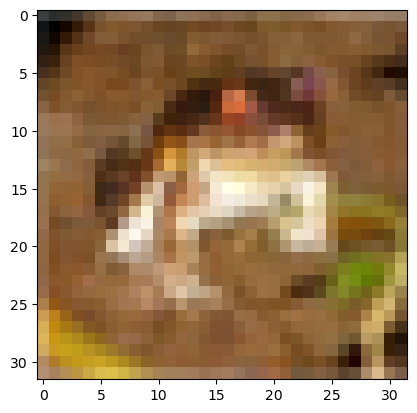

'frog'

In [13]:
# Previewing a sample and calculating mean, std
import matplotlib.pyplot as plt
# len(cifar10_train)

# dynamic tensor to store all images
imgs = torch.stack([img for img, _ in cifar10_train], dim=3)
imgs = imgs.view(3, -1)
imgs.shape

data_mean = imgs.mean(dim=1)
data_std = imgs.std(dim=1)

data_mean, data_std

image, label = cifar10_train[0]
%matplotlib inline
plt.imshow(image.permute(1, 2, 0))
plt.show()
class_names[label]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9892126..2.0945773].


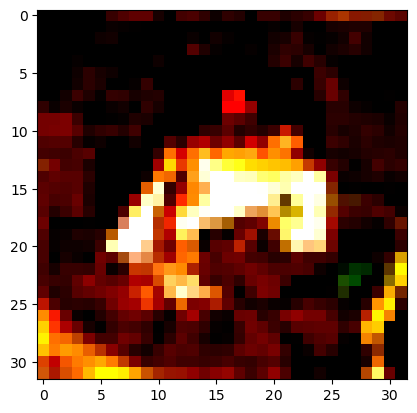

'frog'

In [14]:
# Normalizing the datasets
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean= data_mean.tolist(), std= data_std.tolist())
])

cifar10_train = datasets.CIFAR10(data_path, train=True, download=False, transform=transform)
cifar10_val = datasets.CIFAR10(data_path, train=False, download=False, transform=transform)

image, label = cifar10_train[0]
%matplotlib inline
plt.imshow(image.permute(1, 2, 0))
plt.show()
class_names[label]

In [15]:
# Creating Dataloader
from torch.utils.data import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"

train_loader = DataLoader(cifar10_train, batch_size=5096, shuffle=True, pin_memory=True, pin_memory_device=device, num_workers=8) # Using 8 cores of cpu to load data
val_loader = DataLoader(cifar10_val, batch_size=5096, shuffle=True, pin_memory=True, pin_memory_device=device, num_workers=8) 


In [16]:
# Building the Classifier
import torch
import torch.optim as optim
import torch.nn as nn

n_in = cifar10_train[0][0].numel() # 3 x 32 x 32 = 3072 ...still
n_hidden1 = 1024 * 5
n_hidden2 = 512 * 5
n_hidden3 = 128 * 5
n_out = 10 # Now using 10 images

model = nn.Sequential(
    nn.Linear(n_in, n_hidden1),
    nn.Tanh(),
    nn.Linear(n_hidden1, n_hidden2),
    nn.Tanh(),
    nn.Linear(n_hidden2, n_hidden3),
    nn.Tanh(),
    nn.Linear(n_hidden3, n_out))

model.to(device)

Sequential(
  (0): Linear(in_features=3072, out_features=5120, bias=True)
  (1): Tanh()
  (2): Linear(in_features=5120, out_features=2560, bias=True)
  (3): Tanh()
  (4): Linear(in_features=2560, out_features=640, bias=True)
  (5): Tanh()
  (6): Linear(in_features=640, out_features=10, bias=True)
)

In [17]:
# Building optimizer, loss funtion and training loop

lr = 1e-2
optimizer = optim.Adam(model.parameters(), lr=lr)

loss_fn = nn.CrossEntropyLoss()

n_epochs = 100

def training_loop(train_loader, n_epochs=n_epochs, model=model, optimizer=optimizer, loss_fn=loss_fn):
    for epoch in range (1, n_epochs + 1):
        for image_batch, label_batch in train_loader:
            #move batches to gpu
            image_batch, label_batch = image_batch.to(device), label_batch.to(device)
            # Flatten images to 1D vector
            batch_size = image_batch.shape[0]
            image_batch = image_batch.view(batch_size, -1)

            # Pass data trough model and determine loss
            out = model(image_batch)
            loss = loss_fn(out, label_batch)

            # backproppgate and update params
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # if epoch <= 3 or epoch % 10 == 0:
        print(f'EPOCH {epoch} Loss: {loss}')

In [7]:
# Running training loop
training_loop(train_loader)

KeyboardInterrupt: 

In [20]:
# Validating Model

def validate_model(val_loader, model=model, loss_fn=loss_fn):
    correct, total = 0, 0
    
    with torch.no_grad():
        for image_batch, label_batch in val_loader:
            image_batch, label_batch = image_batch.to(device), label_batch.to(device)
            batch_size = image_batch.shape[0]
            image_batch = image_batch.view(batch_size, -1)
            
            out = model(image_batch)
            _, prediction = torch.max(out, dim=1)
            total += label_batch.shape[0] # Adds # labels in batch to total
            correct += int((prediction == label_batch).sum()) # Increments correct by number of predictions that match label
        print(f'Correctly identified {correct} images out of {total}')
        print(f'Model Accuracy {correct/total*100:.2f}%')

validate_model(val_loader=val_loader)

Correctly identified 986 images out of 10000
Model Accuracy 9.86%


### 1

1. Use torchvision to implelment random cropping of data \
a. How are training results diffrent \
--> Training results decreased, probably becasue it had to capture a lot more patterns with the same model arcetecture, so it preformed more poorly on the val set.
b. what happens when you request the same image a seccond time \
--> Diffrent section of image is shown \
c. what are the results of training using cropped images
--> 70% Cropped accuracy (Identified 1404 Images out of 2000) vs 81 % Regular accuracy (Identified 1636 Images out of 2000)

#### Code

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.1523199..1.8365959].


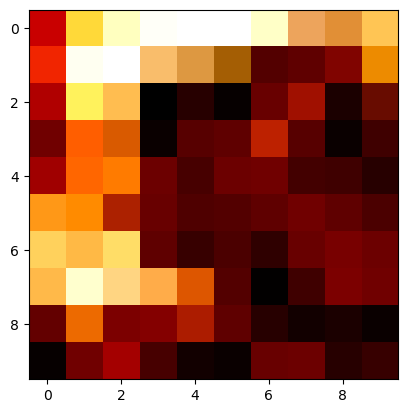

300

In [22]:
# Adding random cropping to transforms
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean= data_mean.tolist(), std= data_std.tolist()),
    transforms.RandomCrop(10)
])

# Transforming dataset
cifar10_train = datasets.CIFAR10(data_path, train=True, download=False, transform=transform)
cifar10_val = datasets.CIFAR10(data_path, train=False, download=False, transform=transform)

# Plotting data
image, label = cifar10_train[0]
%matplotlib inline
plt.imshow(image.permute(1, 2, 0))
plt.show()
class_names[label]

image.numel()

In [24]:
# Remaking dataloaders and model
train_loader_crop = DataLoader(cifar10_train, batch_size=5096, shuffle=True, pin_memory=True, pin_memory_device=device) # Using 8 cores of cpu to load data
val_loader_crop = DataLoader(cifar10_val, batch_size=5096, shuffle=True, pin_memory=True, pin_memory_device=device) 

n_in = cifar10_train[0][0].numel() # Now 3 x 10 x 10 = 300
n_hidden1 = 1024 * 5
n_hidden2 = 512 * 5
n_hidden3 = 128 * 5
n_out = 10 # Now using 10 images

model_cropped = nn.Sequential(
    nn.Linear(n_in, n_hidden1),
    nn.Tanh(),
    nn.Linear(n_hidden1, n_hidden2),
    nn.Tanh(),
    nn.Linear(n_hidden2, n_hidden3),
    nn.Tanh(),
    nn.Linear(n_hidden3, n_out))

model_cropped.to(device)

Sequential(
  (0): Linear(in_features=300, out_features=5120, bias=True)
  (1): Tanh()
  (2): Linear(in_features=5120, out_features=2560, bias=True)
  (3): Tanh()
  (4): Linear(in_features=2560, out_features=640, bias=True)
  (5): Tanh()
  (6): Linear(in_features=640, out_features=10, bias=True)
)

In [26]:
training_loop(train_loader_crop, model=model_cropped, n_epochs=10)

EPOCH 1 Loss: 2.3042209148406982
EPOCH 2 Loss: 2.3026626110076904
EPOCH 3 Loss: 2.303649663925171
EPOCH 4 Loss: 2.303520441055298
EPOCH 5 Loss: 2.3049066066741943
EPOCH 6 Loss: 2.301253080368042
EPOCH 7 Loss: 2.3062338829040527
EPOCH 8 Loss: 2.3020107746124268
EPOCH 9 Loss: 2.3034744262695312
EPOCH 10 Loss: 2.3019888401031494


In [27]:
validate_model(val_loader_crop, model=model_cropped)

Correctly identified 872 images out of 10000
Model Accuracy 8.72%


### 2

2. Switch loss functions (perhaps MSE) \
a. Does the training behavior change? \
-->Training loss was much lower with CrossEntropyLoss, but they preformed almost the same on the validation set \
--> Note: to use MSE, have to switch label to onehot. Could make a preformacne diffrence?


#### Code

In [145]:
import torch
import torch.nn as nn
import torch.optim as optim

connnected_model = nn.Sequential(
    nn.Linear(3072, 1024),
    nn.Tanh(),
    nn.Linear(1024, 512),
    nn.Tanh(),
    nn.Linear(512, 128),
    nn.Tanh(),
    nn.Linear(128, 2))
    # nn.Softmax())

learning_rate = 1e-2

optimizer = optim.SGD(connnected_model.parameters(), lr = learning_rate)

loss_fn = nn.MSELoss()

n_epochs = 100


device = "cuda" if torch.cuda.is_available() else 'cpu'
connnected_model.to(device)

# Training
for epoch in range(1, n_epochs + 1):
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        batch_size = imgs.shape[0]  
        imgs = imgs.view(batch_size, -1) 
        outputs = connnected_model(imgs)

        # Convert labels to one-hot encoding
        labels_onehot = torch.zeros(batch_size, 2).to(device)
        labels_onehot[torch.arange(batch_size), labels] = 1  # One-hot encode the labels
        
        # # Debugging output: check shapes
        # print(f"Outputs shape: {outputs.shape}, Labels shape: {labels_onehot.shape}")
        
        loss = loss_fn(outputs, labels_onehot)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
    print('Epoch %d, Loss: %f' % (epoch, float(loss))) 

Epoch 1, Loss: 0.126290
Epoch 2, Loss: 0.261730
Epoch 3, Loss: 0.112228
Epoch 4, Loss: 0.246532
Epoch 5, Loss: 0.196095
Epoch 6, Loss: 0.113373
Epoch 7, Loss: 0.073017
Epoch 8, Loss: 0.085554
Epoch 9, Loss: 0.084654
Epoch 10, Loss: 0.108123
Epoch 11, Loss: 0.144836
Epoch 12, Loss: 0.227104
Epoch 13, Loss: 0.153189
Epoch 14, Loss: 0.157647
Epoch 15, Loss: 0.113296
Epoch 16, Loss: 0.144364
Epoch 17, Loss: 0.100849
Epoch 18, Loss: 0.070308
Epoch 19, Loss: 0.104329
Epoch 20, Loss: 0.131125
Epoch 21, Loss: 0.079290
Epoch 22, Loss: 0.139642
Epoch 23, Loss: 0.077663
Epoch 24, Loss: 0.195066
Epoch 25, Loss: 0.083535
Epoch 26, Loss: 0.122510
Epoch 27, Loss: 0.077976
Epoch 28, Loss: 0.077434
Epoch 29, Loss: 0.147029
Epoch 30, Loss: 0.083554
Epoch 31, Loss: 0.072445
Epoch 32, Loss: 0.137714
Epoch 33, Loss: 0.061307
Epoch 34, Loss: 0.092318
Epoch 35, Loss: 0.136300
Epoch 36, Loss: 0.044269
Epoch 37, Loss: 0.082236
Epoch 38, Loss: 0.081202
Epoch 39, Loss: 0.092343
Epoch 40, Loss: 0.074033
Epoch 41,

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9892126..2.1267893].



Correctly Identified 1586 Images out of 2000
Model Accuracy 79.300000


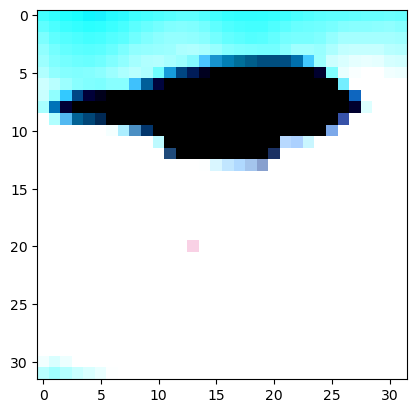

Prediction airplane, True Label: airplane


In [147]:
# Validation
correct, total = 0, 0

with torch.no_grad():
    for imgs, labels in val_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        batch_size = imgs.shape[0]
        imgs = imgs.view(batch_size, -1)
        output = connnected_model(imgs)
        _, predicted = torch.max(output, dim=1) # Get the output with highest prediction prob.
        total += labels.shape[0]
        correct += int((predicted == labels).sum()) # Increases correct counter = # images correctly identified per minibatch

    print()
    print('Correctly Identified %d Images out of %d' % (correct, total))
    print('Model Accuracy %f' % ((correct/total)*100))

imgs[0].shape

index = 0

img = imgs[index].view(3, 32, 32)


%matplotlib inline
plt.imshow(img.permute(1, 2, 0).cpu())
plt.show()
print(f'Prediction {class_names[predicted[index]]}, True Label: {class_names[labels[index]]}')

### 3

3. Is it possible to reduce network capacity so that it stops overfitting? \
a How does the model perform on the validation?
--> Preformance Increases on validation set as parameters, and in turn overfitting is redcued 

#### Code

In [158]:
import torch
import torch.nn as nn
import torch.optim as optim

connnected_model = nn.Sequential(
    nn.Linear(3072, 512),
    nn.Tanh(),
    nn.Linear(512, 128),
    nn.Tanh(),
    nn.Linear(128, 64),
    nn.Tanh(),
    nn.Linear(64, 2))

learning_rate = 1e-2

optimizer = optim.SGD(connnected_model.parameters(), lr = learning_rate)

loss_fn = nn.CrossEntropyLoss()

n_epochs = 100


device = "cuda" if torch.cuda.is_available() else 'cpu'
connnected_model.to(device)

# Training
for epoch in range(1, n_epochs + 1):
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device) # moving to GPU for 
        batch_size = imgs.shape[0]  # imgs.shape = 64 x 3 x 32 x 32
        imgs = imgs.view(batch_size, -1) # Flattining the image, but leaving the batch size -- using view to combine everything but batch_size
        outputs = connnected_model(imgs)
        loss = loss_fn(outputs, labels) #Label cbonverted to tensor in dataloader
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
    print('Epoch %d, Loss: %f' % (epoch, float(loss))) # Loss now prints for random img in dataset

Epoch 1, Loss: 0.344071
Epoch 2, Loss: 0.379763
Epoch 3, Loss: 0.253051
Epoch 4, Loss: 0.502732
Epoch 5, Loss: 0.616756
Epoch 6, Loss: 0.346997
Epoch 7, Loss: 0.371435
Epoch 8, Loss: 0.194203
Epoch 9, Loss: 0.540293
Epoch 10, Loss: 0.251926
Epoch 11, Loss: 0.581624
Epoch 12, Loss: 0.388349
Epoch 13, Loss: 0.234728
Epoch 14, Loss: 0.426631
Epoch 15, Loss: 0.201168
Epoch 16, Loss: 0.299896
Epoch 17, Loss: 0.722587
Epoch 18, Loss: 0.294102
Epoch 19, Loss: 0.414550
Epoch 20, Loss: 0.189531
Epoch 21, Loss: 0.377565
Epoch 22, Loss: 0.260413
Epoch 23, Loss: 0.192292
Epoch 24, Loss: 0.671182
Epoch 25, Loss: 0.313083
Epoch 26, Loss: 0.267871
Epoch 27, Loss: 0.208864
Epoch 28, Loss: 0.092101
Epoch 29, Loss: 0.056297
Epoch 30, Loss: 0.039329
Epoch 31, Loss: 0.117235
Epoch 32, Loss: 0.267541
Epoch 33, Loss: 0.081058
Epoch 34, Loss: 0.069166
Epoch 35, Loss: 0.077452
Epoch 36, Loss: 0.216914
Epoch 37, Loss: 0.313310
Epoch 38, Loss: 0.134207
Epoch 39, Loss: 0.085246
Epoch 40, Loss: 0.390733
Epoch 41,

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9892126..2.1267893].



Correctly Identified 1612 Images out of 2000
Model Accuracy 80.600000

Model Test:


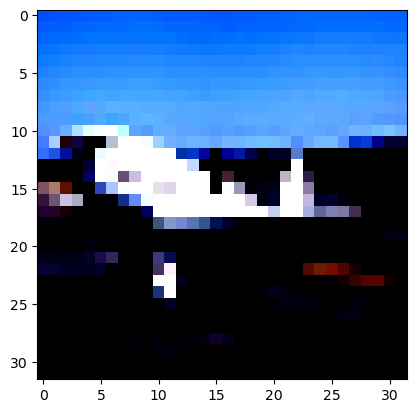

Prediction airplane, True Label: airplane


In [159]:
# Validation
correct, total = 0, 0

with torch.no_grad():
    for imgs, labels in val_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        batch_size = imgs.shape[0]
        imgs = imgs.view(batch_size, -1)
        output = connnected_model(imgs)
        _, predicted = torch.max(output, dim=1) # Get the output with highest prediction prob.
        total += labels.shape[0]
        correct += int((predicted == labels).sum()) # Increases correct counter = # images correctly identified per minibatch

    print()
    print('Correctly Identified %d Images out of %d' % (correct, total))
    print('Model Accuracy %f' % ((correct/total)*100))

imgs.shape

index = 15

img = imgs[index].view(3, 32, 32)


print()
print('Model Test:')
%matplotlib inline
plt.imshow(img.permute(1, 2, 0).cpu())
plt.show()
print(f'Prediction {class_names[predicted[index]]}, True Label: {class_names[labels[index]]}')